# FUT fBVOC emission source: CTRL_PD vs CTRL_FUT emissions

The main notebooks use `LCC_FUT_fBVOCctrlPD` as the FUT fixed-BVOC run (emissions = CTRL_PD climatology, relabelled to 2100). This notebook compares it with `LCC_FUT_fBVOCctrlFUT` (emissions = CTRL_FUT climatology), so the FUT BVOC contrast can be read both ways.
Code: `boreal_forest_expansion.plotting.forcing_maps` (`FBVOC_SOURCE_ROWS`).

| Row | Contrast | What it measures |
|---|---|---|
| 1 | `LCC_FUT − LCC_FUT_fBVOCctrlPD` | the main-notebook BVOC_FUT: LCC emissions vs **PD** CTRL emissions → land-cover change **plus** the climate/CO₂ emission response |
| 2 | `LCC_FUT − LCC_FUT_fBVOCctrlFUT` | LCC emissions vs **FUT** CTRL emissions → closer to the land-cover-only BVOC effect |
| 3 | `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` | same LCC_FUT setup, only the prescribed emissions differ (FUT − PD CTRL climatology) = row 1 − row 2 |

**Data and caveats**
- Input: `data/processed-data/postprocessing/[alias]_[atm|lnd]_[CATEGORY]_2001-2014.nc` (first 12 months dropped). Runs: LCC_FUT `…nudg_lcc_…-20261005`, fBVOC `…nudg_lcc_fBVOCctrlPD/ctrlFUT_…-20261025` (all 19 MEGAN species prescribed; climatologies from CTRL `-20261023`, 2001–2014).
- **Provisional:** old spin-up chain (CO₂ bug in the FUT LCC land spin-up); redo on the CO₂-fix chain.
- A prescribed climatology has no interannual or weather coupling, so even row 2 is not exactly zero where nothing changed.
- Paired yearly differences (14 years); maps: grey hatching = not significant (paired t-test, FDR α = 0.10, cells ≥45°N); ± = 95 % t-interval across years.
- Figures: `results/figures/` (`FUT_ghan_LCC-fBVOCctrl*`, `FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_*`, `contrast_grid_context_FUT-fBVOC-source_*`, `fut_fbvoc_source_seasonal_chain_*`); tables: `results/tables/fut_fbvoc_source_*_2001_2014.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import pandas as pd
import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 200)
START_YEAR, END_YEAR = 2001, 2014
ROWS = fm.FBVOC_SOURCE_ROWS
FIGDIR = fm.FIGURE_DIR   # main figure folder (user 2026-10-28)
TABLES = fm.REPO_DIR / "results" / "tables"
CTRL_FUT = fm.BVOC_PAIRS["FUT"]["ctrl"]

for alias in sorted({a for r in ROWS for a in r}):
    for cls in ("BVOC", "SOA", "RADIATIVE"):
        path = fm.filename(alias, cls, START_YEAR, END_YEAR)
        print(path.name, "✓" if path.exists() else "MISSING")

LCC_FUT_atm_BVOC_2001-2014.nc ✓
LCC_FUT_atm_SOA_2001-2014.nc ✓
LCC_FUT_atm_RADIATIVE_2001-2014.nc ✓
LCC_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc ✓
LCC_FUT_fBVOCctrlFUT_atm_SOA_2001-2014.nc ✓
LCC_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc ✓
LCC_FUT_fBVOCctrlPD_atm_BVOC_2001-2014.nc ✓
LCC_FUT_fBVOCctrlPD_atm_SOA_2001-2014.nc ✓
LCC_FUT_fBVOCctrlPD_atm_RADIATIVE_2001-2014.nc ✓


## 1. Emissions: annual totals (Tg yr⁻¹)
Mean over the years of the annual sum of monthly totals; early 2001–2007, late 2008–2014. Row 3 shows how different the two prescribed climatologies are.

In [2]:
rows = []
for c1, c2 in ROWS:
    for region in ("modified cells", "unmodified land ≥45°N", "≥45°N"):
        for field in ("SFISOP_Tg", "SFMTERP_Tg"):
            d = fm.monthly_difference(c1, c2, field, region, start_year=START_YEAR, end_year=END_YEAR).sum("month")
            rows.append(dict(contrast=f"{c1} − {c2}", region=region, field=field, all_years=float(d.mean()),
                             early=float(d.sel(year=slice(*fm.EARLY_YEARS)).mean()),
                             late=float(d.sel(year=slice(*fm.LATE_YEARS)).mean())))
emis = pd.DataFrame(rows)
emis.to_csv(TABLES / f"fut_fbvoc_source_emissions_{START_YEAR}_{END_YEAR}.csv", index=False)
emis.round(3)

,contrast,region,field,all_years,early,late
0,LCC_FUT − LCC_FUT_fBVOCctrlPD,modified cells,SFISOP_Tg,8.728,8.703,8.754
1,LCC_FUT − LCC_FUT_fBVOCctrlPD,modified cells,SFMTERP_Tg,17.508,17.412,17.603
2,LCC_FUT − LCC_FUT_fBVOCctrlPD,unmodified land ≥45°N,SFISOP_Tg,5.528,5.364,5.693
3,LCC_FUT − LCC_FUT_fBVOCctrlPD,unmodified land ≥45°N,SFMTERP_Tg,9.273,9.177,9.369
4,LCC_FUT − LCC_FUT_fBVOCctrlPD,≥45°N,SFISOP_Tg,14.257,14.067,14.446
5,LCC_FUT − LCC_FUT_fBVOCctrlPD,≥45°N,SFMTERP_Tg,26.781,26.589,26.973
6,LCC_FUT − LCC_FUT_fBVOCctrlFUT,modified cells,SFISOP_Tg,0.368,0.342,0.393
7,LCC_FUT − LCC_FUT_fBVOCctrlFUT,modified cells,SFMTERP_Tg,-0.108,-0.204,-0.013
8,LCC_FUT − LCC_FUT_fBVOCctrlFUT,unmodified land ≥45°N,SFISOP_Tg,0.031,-0.134,0.195
9,LCC_FUT − LCC_FUT_fBVOCctrlFUT,unmodified land ≥45°N,SFMTERP_Tg,0.032,-0.064,0.128


## 2. Radiative budget, regional means (W m⁻²)
Ghan terms (total = ARI + cloud + clear-clean) for NET, SW, LW; ≥45°N and modified cells; mean ± 95 % CI across years.

In [3]:
ref = fm.open_class(CTRL_FUT, "RADIATIVE", START_YEAR, END_YEAR)
masks = fm.region_masks(ref)
rows = []
for c1, c2 in ROWS:
    for band in ("NET", "SW", "LW"):
        for term in fm.GHAN_TERMS:
            d = fm.yearly_difference(c1, c2, "RADIATIVE", f"{band}_{term}", START_YEAR, END_YEAR)
            for region in ("≥45°N", "modified cells"):
                r = fm.regional(d, ref, masks[region])
                rows += [dict(contrast=f"{c1} − {c2}", region=region, band=band, term=term, year=int(y), value=float(v))
                         for y, v in zip(r["year"].values, r.values)]
budget = pd.DataFrame(rows)
g = budget.pivot_table(index=["contrast", "region", "band", "year"], columns="term", values="value")
print(f"Closure: max |ARI + cloud + clear-clean − total| = {(g['dir'] + g['cloud'] + g['rest'] - g['toa']).abs().max():.1e} W m-2")
summary = fm.summarize_years(budget, ["contrast", "region", "band", "term"])
summary.to_csv(TABLES / f"fut_fbvoc_source_radiative_budget_{START_YEAR}_{END_YEAR}.csv", index=False)
summary.pivot_table(index=["region", "band", "contrast"], columns="term", values=["mean", "ci95"]).round(3)

Closure: max |ARI + cloud + clear-clean − total| = 1.4e-07 W m-2


ci95                        mean                     
term                                                            cloud    dir   rest    toa  cloud    dir   rest    toa
region         band contrast                                                                                          
modified cells LW   LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.093  0.001  0.014  0.099  0.036 -0.000 -0.020  0.015
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.071  0.001  0.014  0.082  0.019  0.008  0.160  0.186
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.048  0.001  0.013  0.052 -0.018  0.008  0.180  0.171
               NET  LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.059  0.012  0.013  0.057  0.057 -0.002 -0.021  0.034
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.065  0.013  0.017  0.071 -1.115 -0.057  0.065 -1.107
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.041  0.012  0.016  0.033 -1.172 -0.055  0.086 -1.141
               SW   LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.110  0.014  0.012  0.125  0.021 -0.002 -0.000  0.019
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.096  0.014  0.014  0.112 -1.133 -0.065 -0.095 -1.293
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.055  0.013  0.011  0.061 -1.154 -0.064 -0.094 -1.312
≥45°N          LW   LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.077  0.001  0.012  0.083  0.027 -0.000 -0.013  0.014
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.055  0.001  0.012  0.063  0.010  0.008  0.169  0.187
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.040  0.001  0.010  0.043 -0.017  0.009  0.182  0.173
               NET  LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.044  0.014  0.013  0.040  0.045 -0.002 -0.012  0.031
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.043  0.015  0.013  0.049 -1.007 -0.034  0.132 -0.908
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.024  0.013  0.013  0.023 -1.052 -0.031  0.144 -0.939
               SW   LCC_FUT − LCC_FUT_fBVOCctrlFUT              0.086  0.016  0.007  0.100  0.018 -0.002  0.001  0.017
                    LCC_FUT − LCC_FUT_fBVOCctrlPD               0.066  0.016  0.008  0.082 -1.017 -0.042 -0.037 -1.095
                    LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD  0.036  0.014  0.006  0.046 -1.035 -0.040 -0.038 -1.112

## 3. BVOC → SOA → cloud maps (rows = the three contrasts)

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_context_FUT-fBVOC-source_2001_2014.png


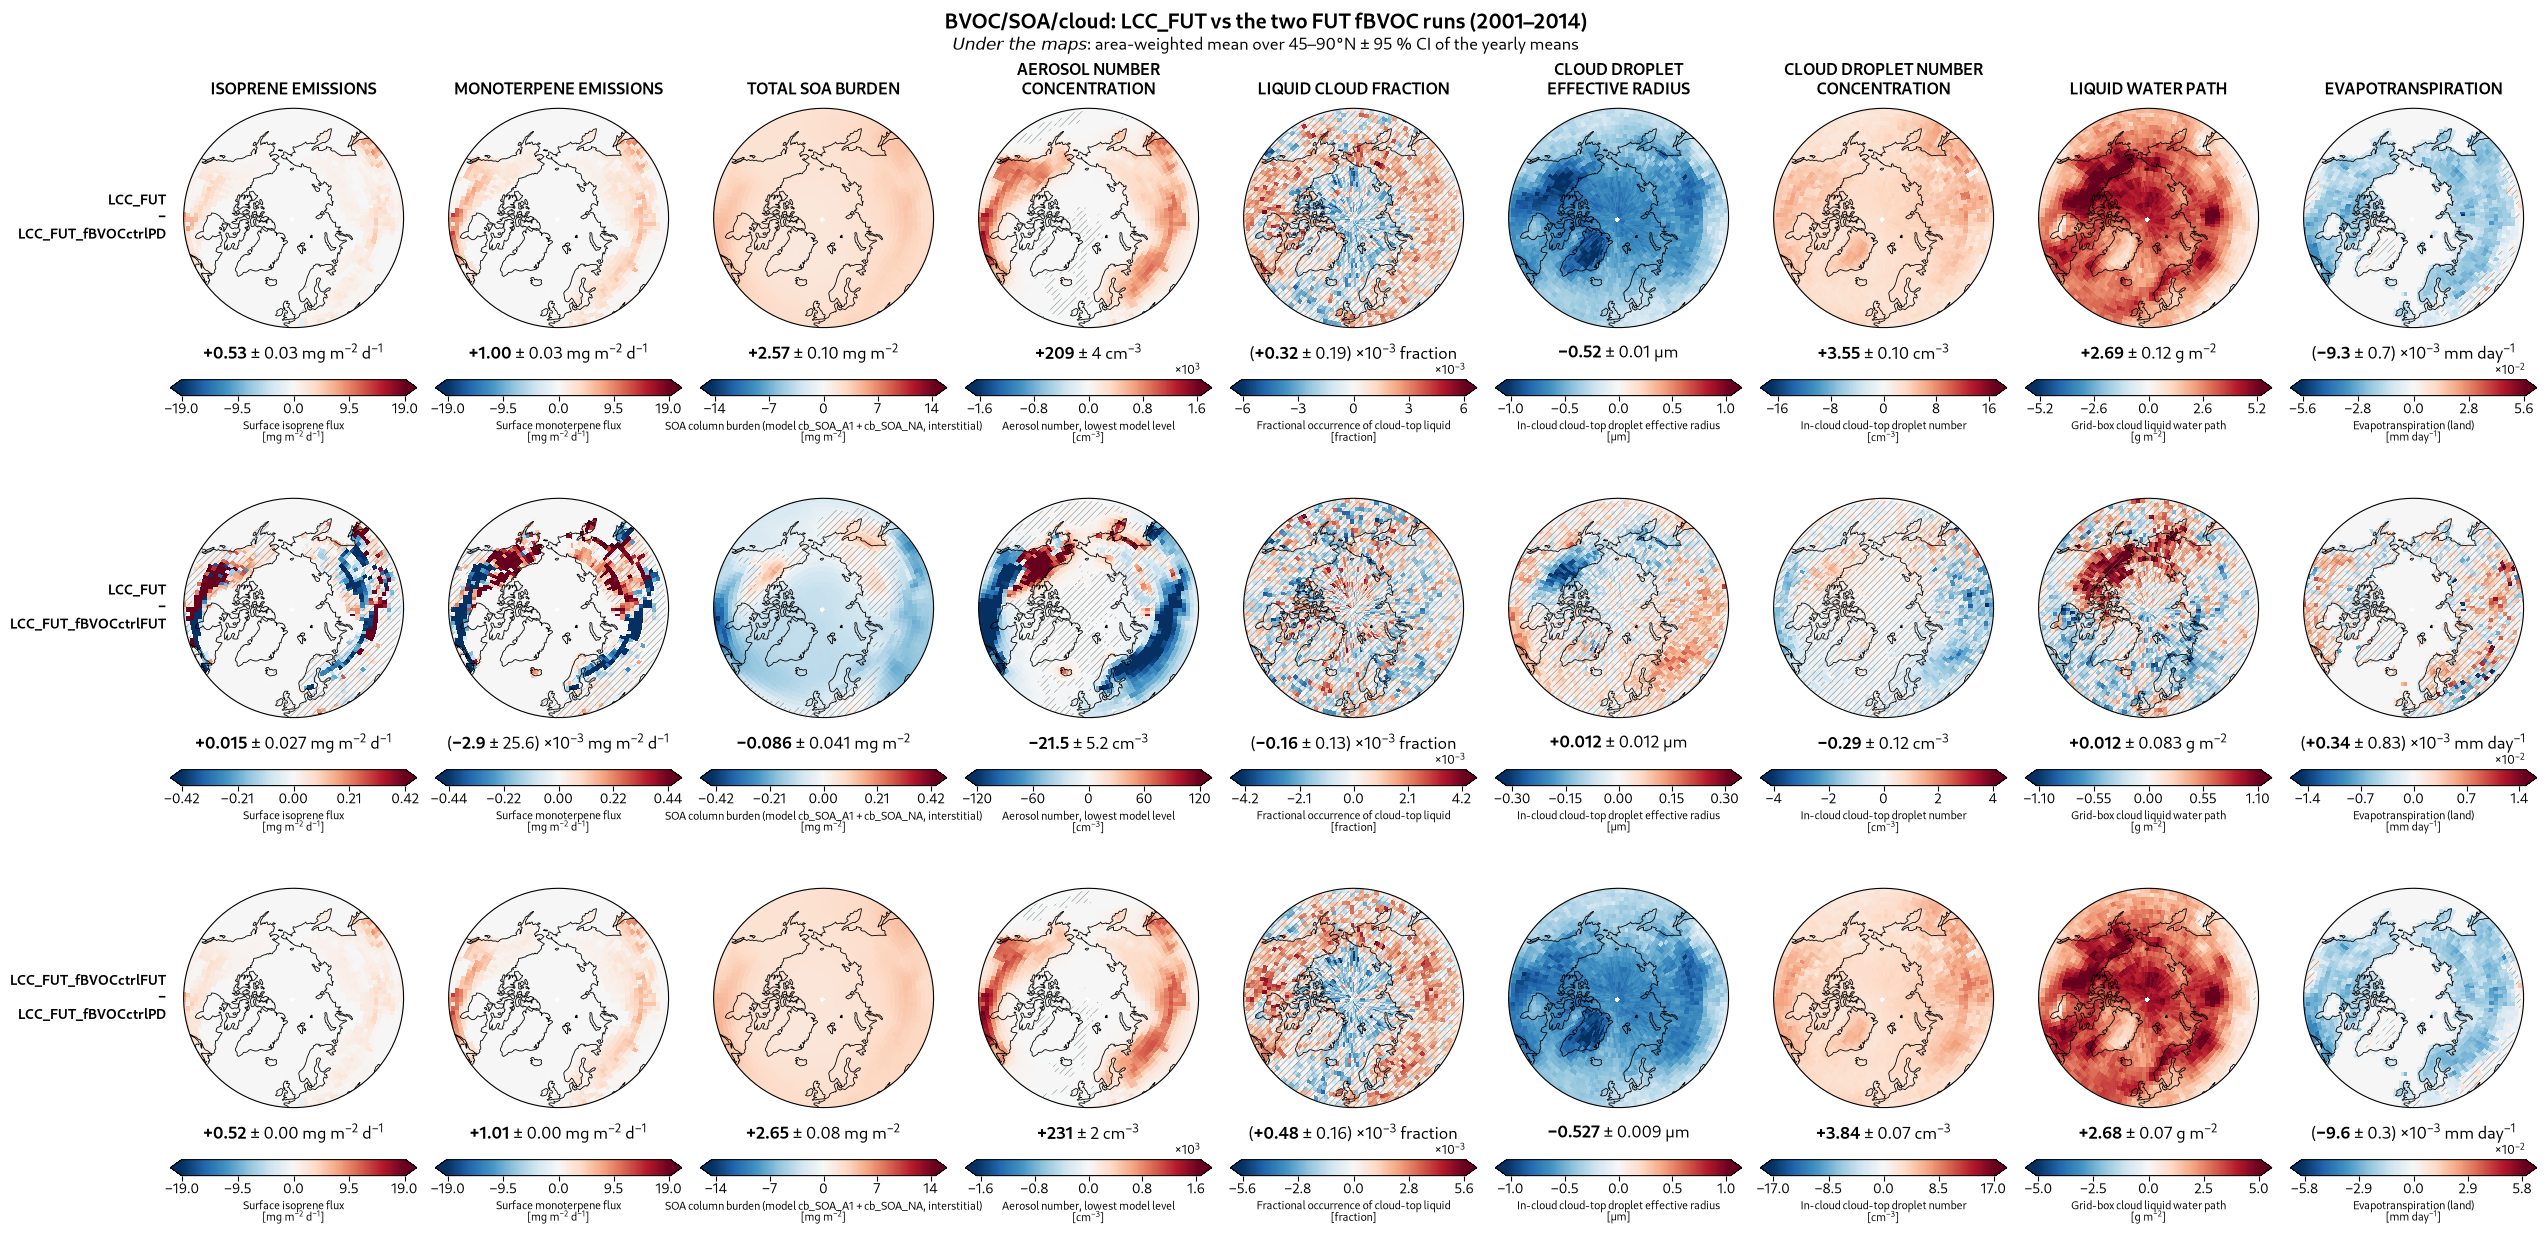

In [4]:
fig, axes = fm.make_contrast_grid_figure("FUT-fBVOC-source", fm.CONTEXT_PANELS, "context", rows=ROWS,
                                         start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
plt.show(); plt.close(fig)

## 4. Ghan decomposition maps, annual (one figure per contrast and band)

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 7.1e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlPD_NET_2001_2014.png


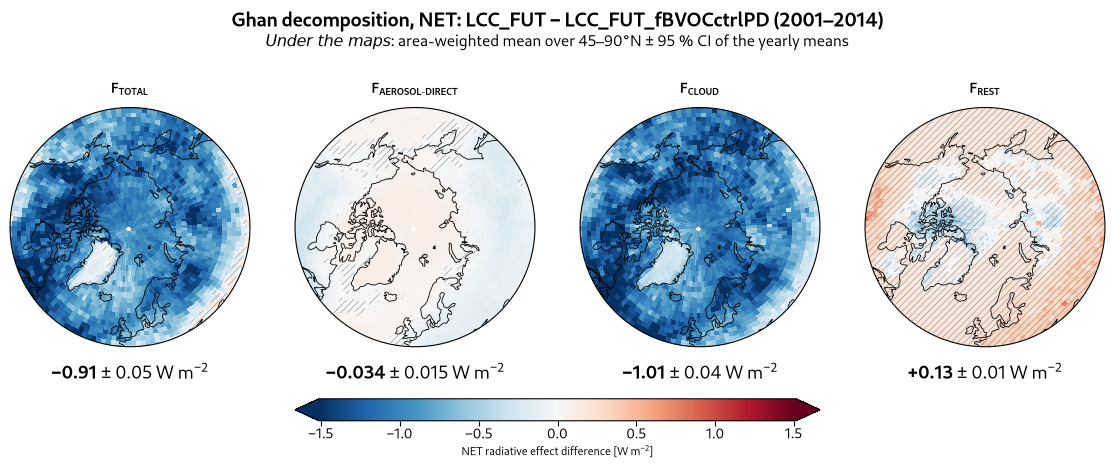

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlPD_SW_2001_2014.png


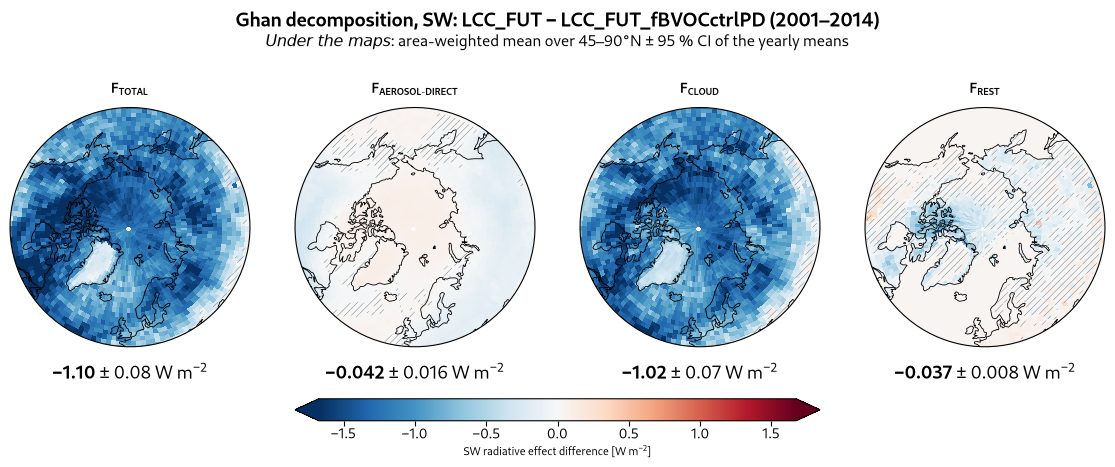

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlPD_LW_2001_2014.png


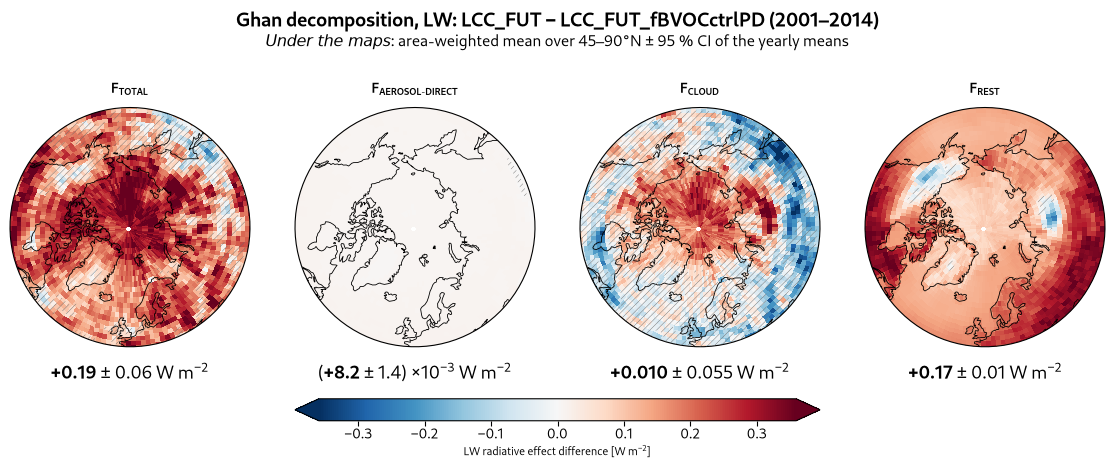

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 6.8e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlFUT_NET_2001_2014.png


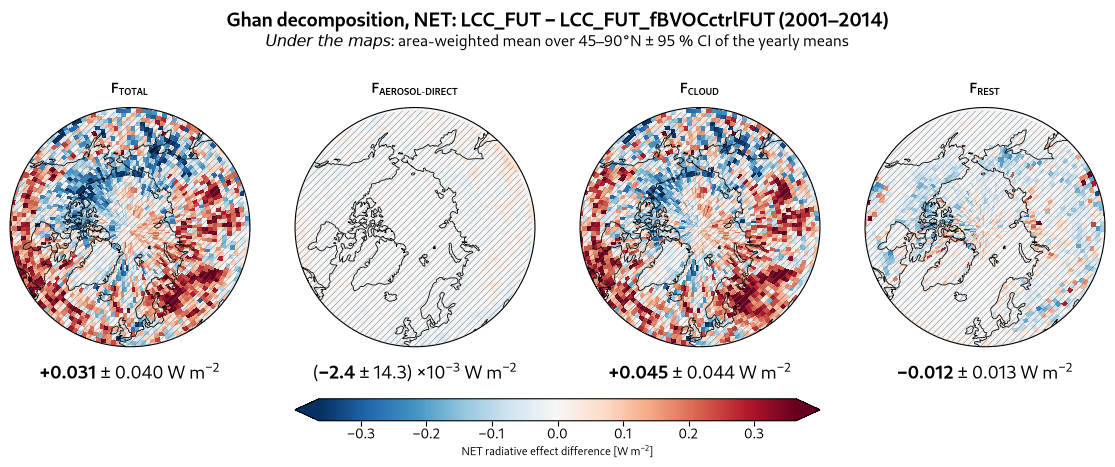

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlFUT_SW_2001_2014.png


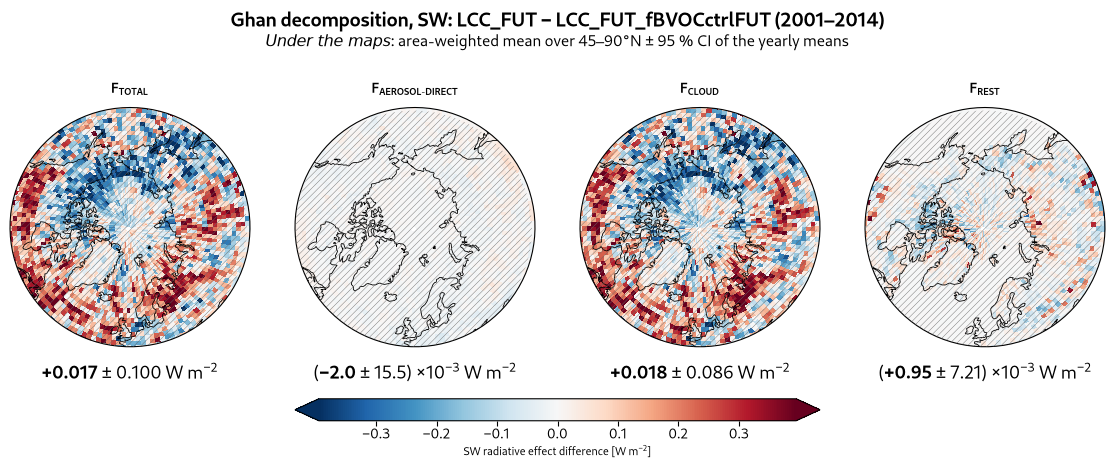

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_LCC-fBVOCctrlFUT_LW_2001_2014.png


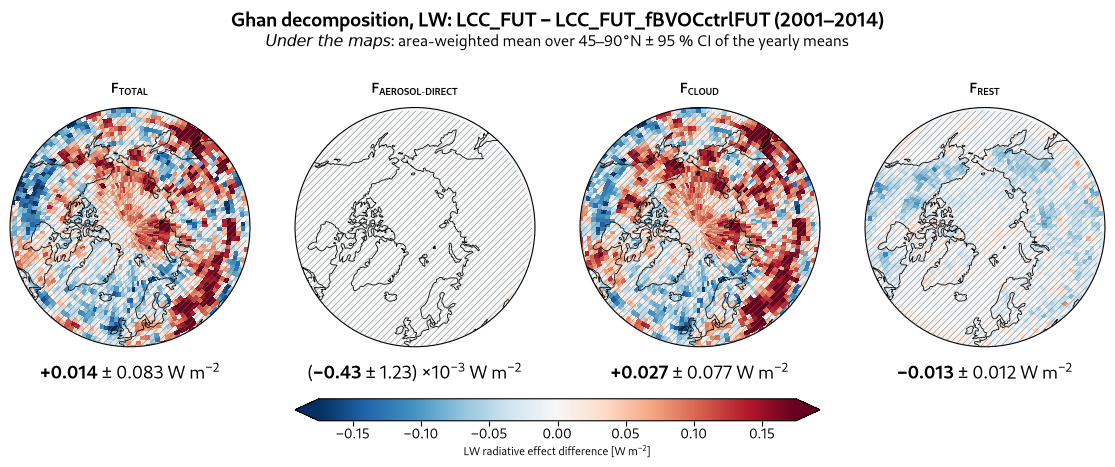

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 7.1e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_NET_2001_2014.png


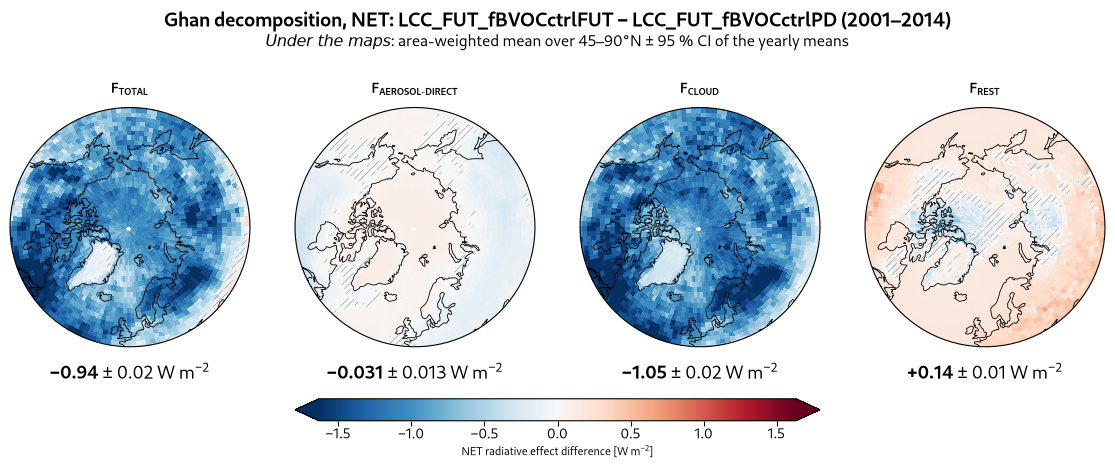

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_SW_2001_2014.png


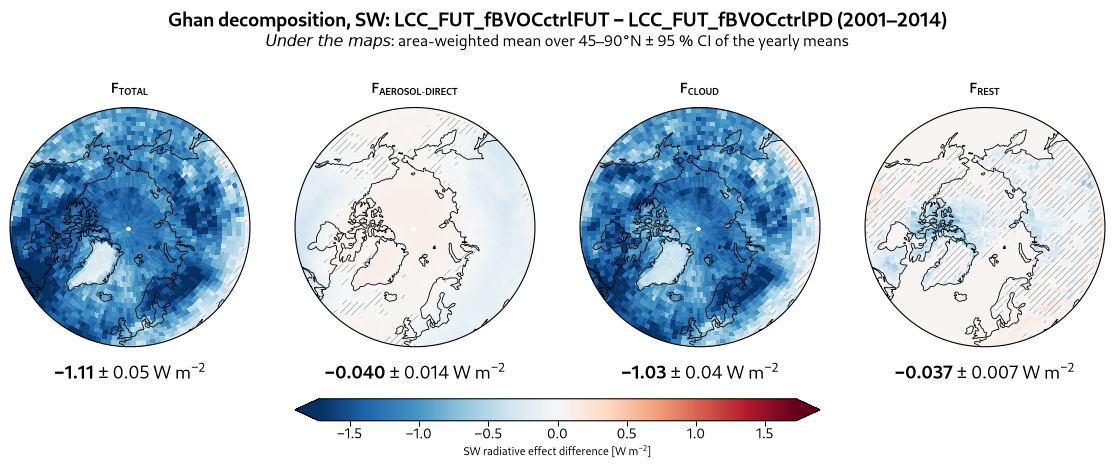

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_LW_2001_2014.png


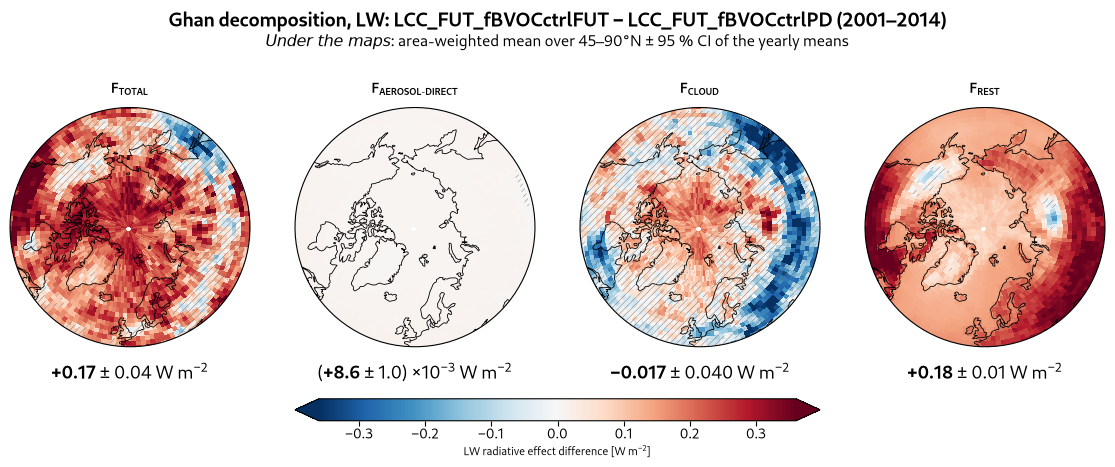

In [5]:
for c1, c2 in ROWS:
    pairs = {"lcc": c1, "fbvoc": c2, "ctrl": CTRL_FUT}
    for band in ("NET", "SW", "LW"):
        fig, axes = fm.make_ghan_figure("FUT", "bvoc", band, pairs=pairs,   # file FUT_ghan_<c1>-<c2>_<band>
                                        start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
        plt.show(); plt.close(fig)

## 5. Seasonal chain: emissions → SOA → aerosol → cloud → SW

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/fut_fbvoc_source_seasonal_chain_2001_2014.png


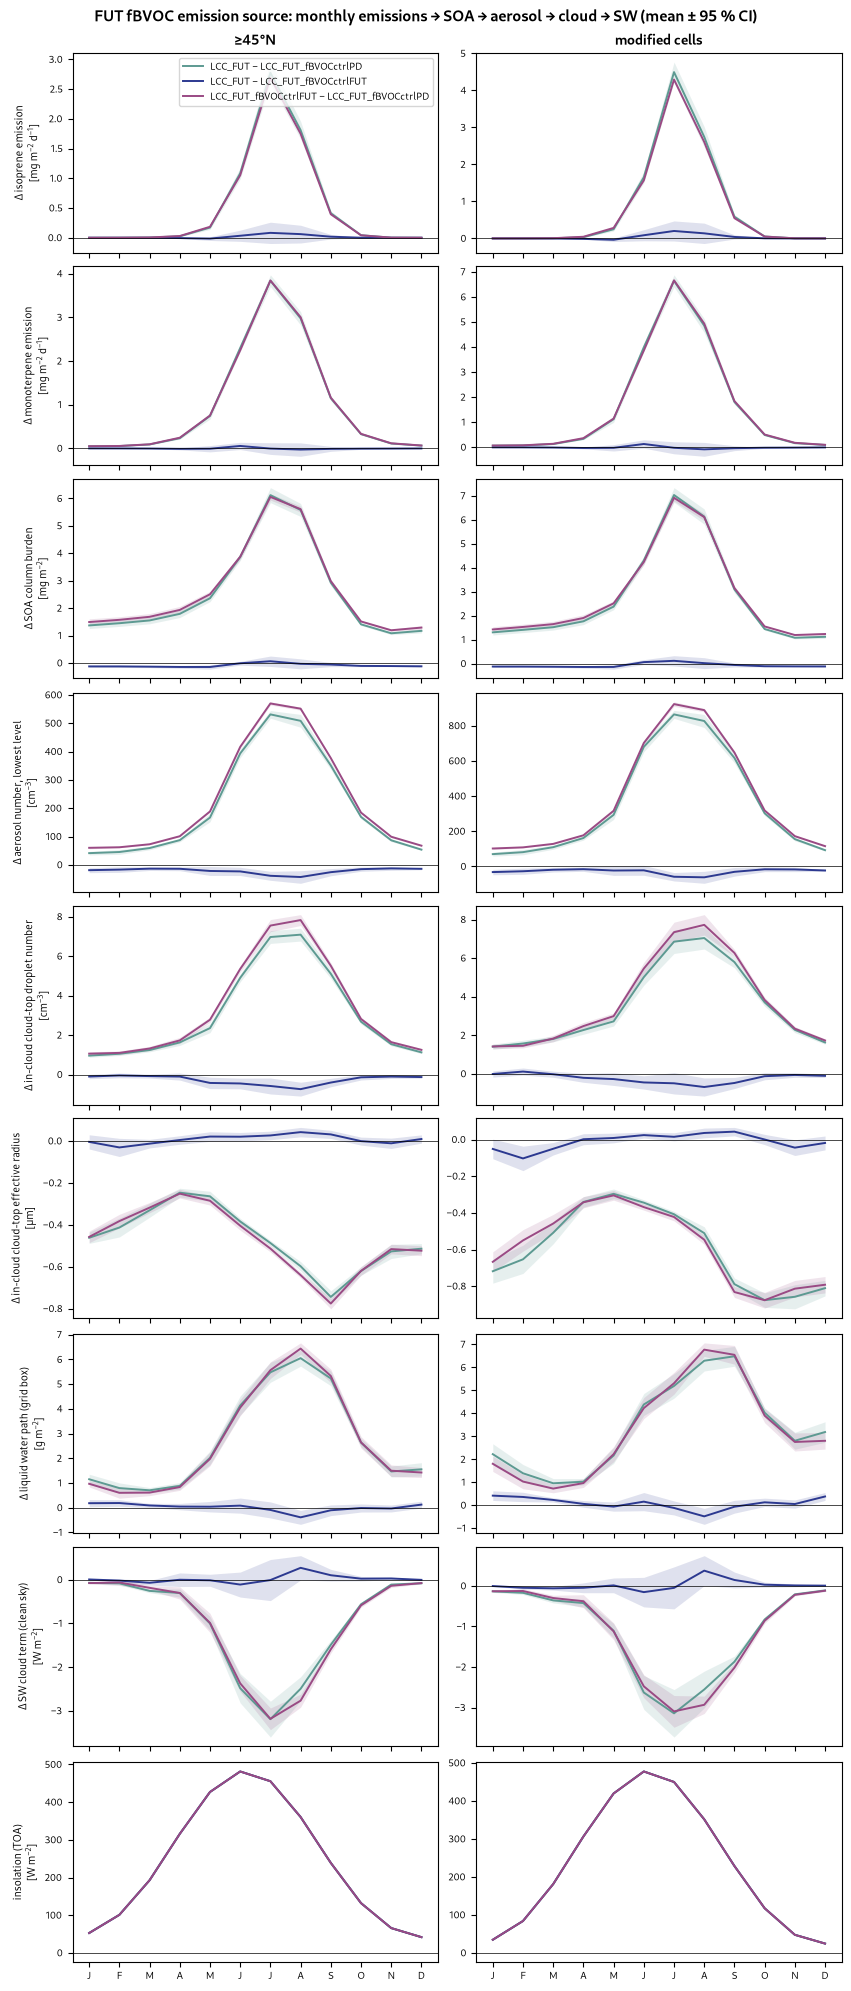

In [6]:
from boreal_forest_expansion.plotting import palette as pal   # project palette (2026-11-03)
colors = pal.PALETTE_ORDER[:3]   # teal, navy, plum (palette order)
lines = {f"{c1} − {c2}": (c1, c2, col, "-") for (c1, c2), col in zip(ROWS, colors)}
fig, axes = fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "cbSOA", "N_AER", "ACTNL_incld", "ACTREL_incld", "TGCLDLWP", "SW_cloud"],
    ["≥45°N", "modified cells"], lines, "fut_fbvoc_source_seasonal_chain",
    "FUT fBVOC emission source: monthly emissions → SOA → aerosol → cloud → SW (mean ± 95 % CI)",
    context="SOLIN", start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
plt.show(); plt.close(fig)